## 01_import_libraries


In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
from google.colab import files


## 02_load_dataset





dataSet source c'est :

https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis

les fichiers utiliser sont  :
 orders.csv , order_products__prior.csv ,order_products__train.csv , products.csv ,aisles.csv ,departments.csv

Objectif :
Analyser les habitudes d'achat des clients et construire un système simple de recommandation basé sur les co-occurrences de produits.

In [36]:
data_path = '/content/drive/MyDrive/dataexplo/archive (1)/'
print("Chargement des fichiers en mémoire...")

orders = pd.read_csv(data_path + 'orders.csv')
products = pd.read_csv(data_path + 'products.csv')
aisles = pd.read_csv(data_path + 'aisles.csv')
departments = pd.read_csv(data_path + 'departments.csv')
order_products_prior = pd.read_csv(
    data_path + 'order_products__prior.csv'
)

order_products_train = pd.read_csv(
    data_path + 'order_products__train.csv'
)

print("Chargement terminé avec succès !")
print(f"orders : {orders.shape}")
print(f"products : {products.shape}")
print(f"aisles : {aisles.shape}")
print(f"departments : {departments.shape}")
print("Order Products Prior :", order_products_prior.shape)
print("Order Products Train :", order_products_train.shape)


Chargement des fichiers en mémoire...
Chargement terminé avec succès !
orders : (3421083, 7)
products : (49688, 4)
aisles : (134, 2)
departments : (21, 2)
Order Products Prior : (32434489, 4)
Order Products Train : (1384617, 4)


## 03_problem_understanding









**Problématique : Quels produits sont fréquemment achetés ensemble et comment proposer des recommandations simples ?**

L’objectif de ce projet est d’analyser les données d’Instacart afin d’identifier les produits souvent achetés ensemble et de construire un système simple de recommandation basé sur les associations observées dans les commandes des clients.


##04_dataset_description




In [37]:
print("Orders :", orders.shape)
print("Order Products Prior :", order_products_prior.shape)
print("Order Products Train :", order_products_train.shape)

Orders : (3421083, 7)
Order Products Prior : (32434489, 4)
Order Products Train : (1384617, 4)


Le dataset utilisé contient :

3421083 commandes

32434489 lignes d'achats historiques

1384617lignes d'achats d'entraînement


## 05_exploratory_data_analysis

In [38]:
#question 2 Limiter obligatoirement l’analyse à un échantillon contrôlé, par exemple 50 000 à 100 000 commandes....


print("Taille initiale de la table orders :", orders.shape)

sampled_orders = orders.sample(n=100000, random_state=42)
print("Taille de la table orders après échantillonnage :", sampled_orders.shape)

Taille initiale de la table orders : (3421083, 7)
Taille de la table orders après échantillonnage : (100000, 7)


In [39]:
#question 3 : Joindre les tables afin d’obtenir des lignes commande-produit avec nom de produit, rayon et département.
order_products = pd.concat([order_products_prior, order_products_train])

print("Début des jointures...")

df_merged = sampled_orders.merge(order_products, on='order_id', how='inner')

df_merged = df_merged.merge(products, on='product_id', how='inner')

df_merged = df_merged.merge(departments, on='department_id', how='inner')

df_merged = df_merged.merge(aisles, on='aisle_id', how='inner')

print("Jointures terminées ! Dimensions du dataset final :", df_merged.shape)

display(df_merged.head())

Début des jointures...
Jointures terminées ! Dimensions du dataset final : (991664, 15)


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,department,aisle
0,1725437,89960,prior,5,0,14,14.0,35715,1,0,"Whole Grain Organic Waffles, Totally Original",52,1,frozen,frozen breakfast
1,1725437,89960,prior,5,0,14,14.0,13176,2,0,Bag of Organic Bananas,24,4,produce,fresh fruits
2,1725437,89960,prior,5,0,14,14.0,6187,3,1,Raisin Bran Cereal,121,14,breakfast,cereal
3,1725437,89960,prior,5,0,14,14.0,6948,4,1,Organic Original Almond Milk,91,16,dairy eggs,soy lactosefree
4,1725437,89960,prior,5,0,14,14.0,25146,5,1,Original Orange Juice,31,7,beverages,refrigerated


/tmp/ipykernel_920/2393364871.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_products.index, x=top_products.values,palette="Blues_r", legend=False)


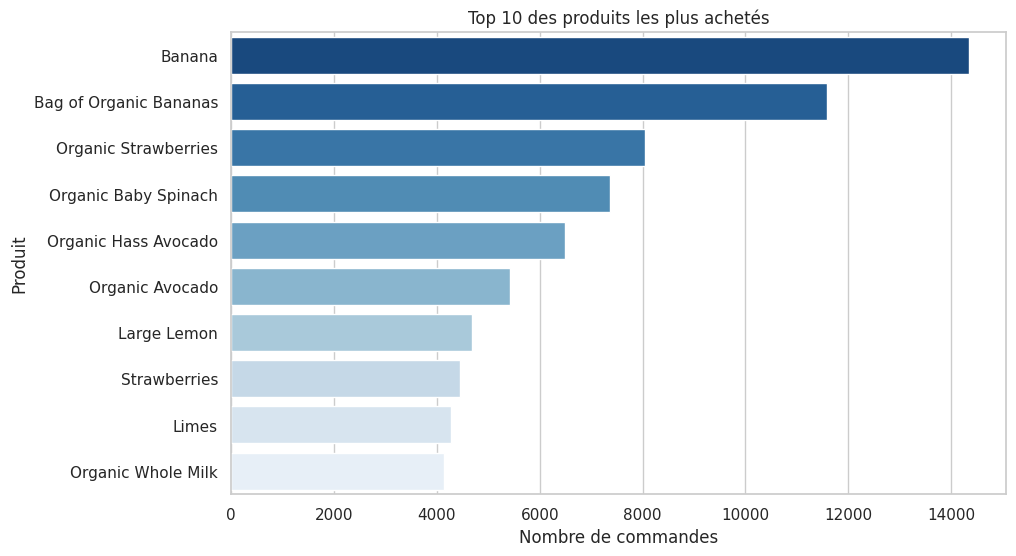

 Les produits les plus achetés sont principalement des produits frais (fruits et légumes).


In [40]:

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
top_products = df_merged['product_name'].value_counts().head(10)
sns.barplot(y=top_products.index, x=top_products.values,palette="Blues_r", legend=False)
plt.title("Top 10 des produits les plus achetés")
plt.xlabel("Nombre de commandes")
plt.ylabel("Produit")
plt.show()
print(" Les produits les plus achetés sont principalement des produits frais (fruits et légumes).")

/tmp/ipykernel_920/2407320637.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_departments.index, x=top_departments.values, palette="Greens_r")


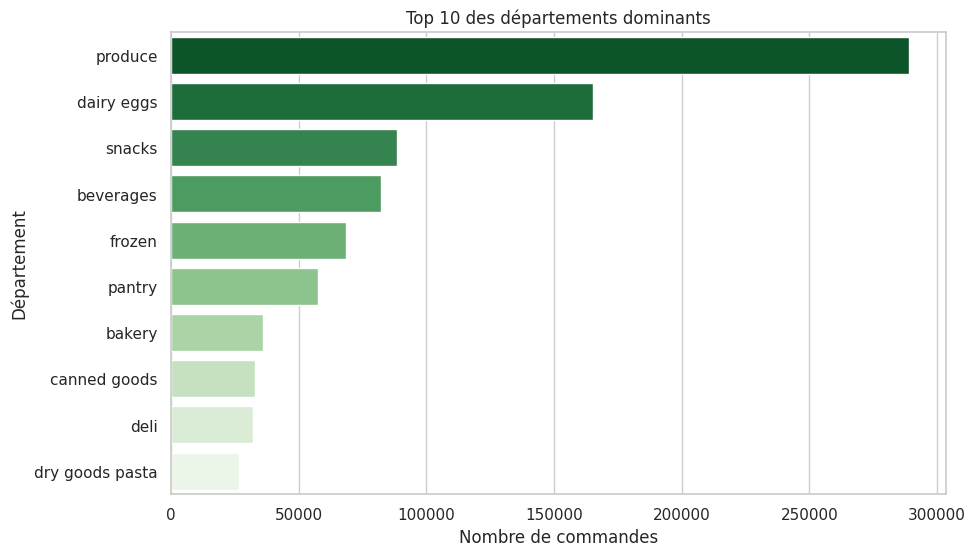

 Le département 'produce' (fruits et légumes) domine largement les ventes.


In [41]:
plt.figure(figsize=(10, 6))
top_departments = df_merged['department'].value_counts().head(10)
sns.barplot(y=top_departments.index, x=top_departments.values, palette="Greens_r")
plt.title("Top 10 des départements dominants")
plt.xlabel("Nombre de commandes")
plt.ylabel("Département")
plt.show()
print(" Le département 'produce' (fruits et légumes) domine largement les ventes.")

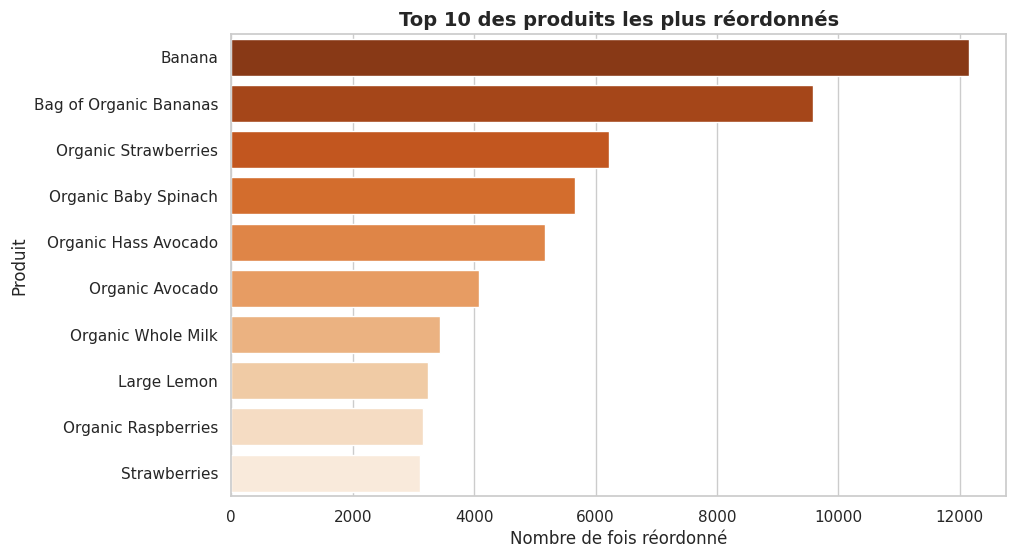

--- RÉSULTAT POUR LE RAPPORT ---
Produit le plus réordonné : Banana (12157 fois)


In [42]:


plt.figure(figsize=(10, 6))

top_reordered = df_merged[df_merged['reordered'] == 1]['product_name'].value_counts().head(10)

sns.barplot(y=top_reordered.index, x=top_reordered.values,
            hue=top_reordered.index, palette="Oranges_r", legend=False)

plt.title("Top 10 des produits les plus réordonnés", fontsize=14, fontweight='bold')
plt.xlabel("Nombre de fois réordonné")
plt.ylabel("Produit")

plt.show()

print("--- RÉSULTAT POUR LE RAPPORT ---")
print(f"Produit le plus réordonné : {top_reordered.index[0]} ({top_reordered.values[0]} fois)")

                                product_name  reorder_ratio
25215                  Plain Soymilk Creamer       0.944444
5882                        Chocolate Crepes       0.900000
22396       Organic Reduced Fat Omega-3 Milk       0.895706
13438        Half And Half Ultra Pasteurized       0.890244
9729                  Enlighten Mint Organic       0.877193
34108                          Water Mineral       0.877193
21491         Organic Homogenized Whole Milk       0.875969
33551                       Variety Diet Tea       0.873016
26005         Protein Bar, Chocolate Pretzel       0.867925
22393  Organic Reduced Fat 2% Cottage Cheese       0.859375


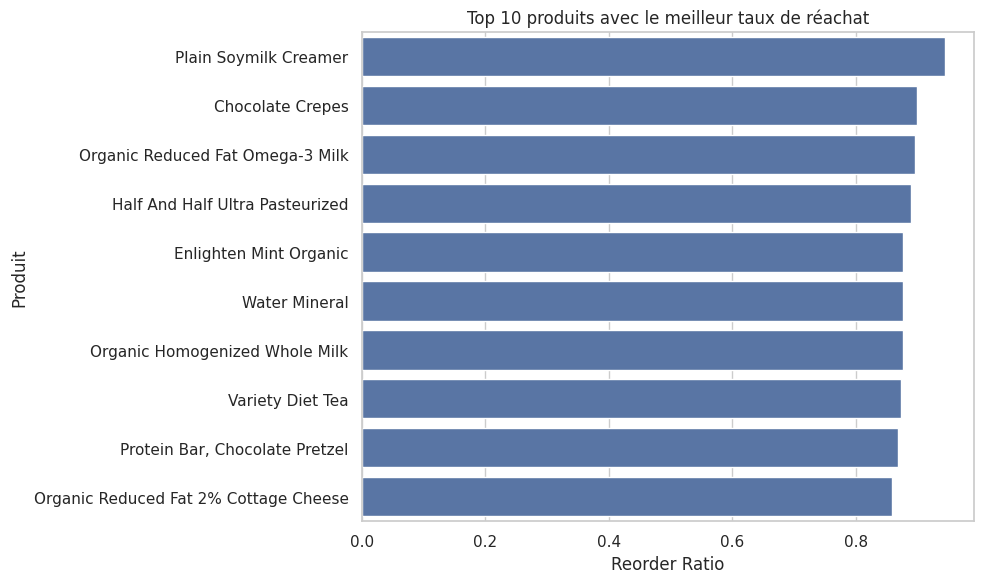

In [43]:
reorder_by_product = (df_merged.groupby('product_name')['reordered']
                      .mean()
                      .reset_index()
                      .rename(columns={'reordered': 'reorder_ratio'})
                      .sort_values('reorder_ratio', ascending=False))

#Filtrer les produits avec au moins 50 achats pour avoir des stats fiables
product_counts = df_merged['product_name'].value_counts()
popular_products = product_counts[product_counts >= 50].index
reorder_by_product_filtered = reorder_by_product[
    reorder_by_product['product_name'].isin(popular_products)
].head(10)

print(reorder_by_product_filtered)

plt.figure(figsize=(10, 6))
sns.barplot(data=reorder_by_product_filtered,
            x='reorder_ratio',
            y='product_name')
plt.title("Top 10 produits avec le meilleur taux de réachat")
plt.xlabel("Reorder Ratio")
plt.ylabel("Produit")
plt.tight_layout()
plt.show()

         department  reorder_ratio
7        dairy eggs       0.668310
3         beverages       0.652584
19          produce       0.648796
2            bakery       0.624293
5              bulk       0.616500
8              deli       0.605982
18             pets       0.586858
1            babies       0.580779
20           snacks       0.570100
0           alcohol       0.563659
13     meat seafood       0.561732
4         breakfast       0.555340
10           frozen       0.537899
9   dry goods pasta       0.457115
6      canned goods       0.453001
14          missing       0.401060
11        household       0.399440
15            other       0.391779
12    international       0.361705
16           pantry       0.345141
17    personal care       0.320913


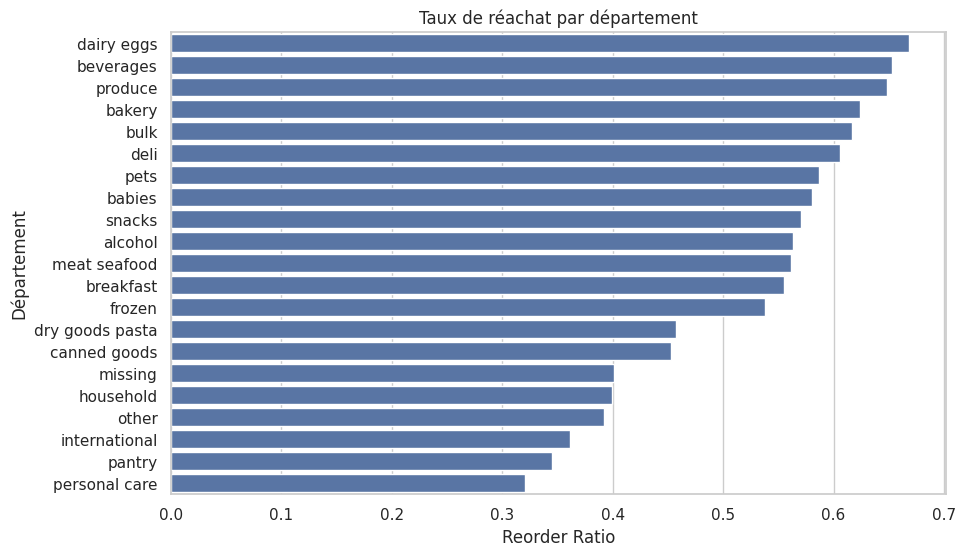

In [44]:
#5 département vc reorder
reorder_by_dept = (df_merged.groupby('department')['reordered']
                   .mean()
                   .reset_index()
                   .rename(columns={'reordered': 'reorder_ratio'})
                   .sort_values('reorder_ratio', ascending=False))


print(reorder_by_dept)

plt.figure(figsize=(10, 6))
sns.barplot(data=reorder_by_dept,
            x='reorder_ratio',
            y='department')
plt.title("Taux de réachat par département")
plt.xlabel("Reorder Ratio")
plt.ylabel("Département")

plt.show()

##06_data_quality_and_cleaning

In [45]:
# Recharger products si nécessaire
products = pd.read_csv(data_path + 'products.csv')

datasets = {
    "orders": orders,
    "products": products,
    "aisles": aisles,
    "departments": departments,
    "order_products_prior": order_products_prior,
    "order_products_train": order_products_train
}

print("=== Valeurs manquantes ===")
for name, df in datasets.items():
    print(f"{name} : {df.isnull().sum().sum()}")

print("\n=== Doublons ===")
for name, df in datasets.items():
    print(f"{name} : {df.duplicated().sum()}")

print("\n=== Contrôles de cohérence ===")
print("order_dow valide :", orders['order_dow'].between(0, 6).all())
print("order_hour_of_day valide :", orders['order_hour_of_day'].between(0, 23).all())
print(
    "days_since_prior_order valide :",
    orders['days_since_prior_order'].dropna().between(0, 30).all()
)

=== Valeurs manquantes ===
orders : 206209
products : 0
aisles : 0
departments : 0
order_products_prior : 0
order_products_train : 0

=== Doublons ===
orders : 0
products : 0
aisles : 0
departments : 0
order_products_prior : 0
order_products_train : 0

=== Contrôles de cohérence ===
order_dow valide : True
order_hour_of_day valide : True
days_since_prior_order valide : True


## 07_preprocessing

In [46]:

sample_orders = df_merged['order_id'].unique()[:5000]
df_sample = df_merged[df_merged['order_id'].isin(sample_orders)]


basket_matrix = (df_sample.groupby(['order_id', 'product_name'])['product_id']
                 .count()
                 .unstack(fill_value=0))

basket_matrix = (basket_matrix > 0).astype(int)

print("Dimensions de la matrice :", basket_matrix.shape)
print(basket_matrix.iloc[:5, :5])

Dimensions de la matrice : (5000, 11874)
product_name  #2 Coffee Filters  0% Fat Free Organic Milk  \
order_id                                                    
322                           0                         0   
393                           0                         0   
520                           0                         0   
816                           0                         0   
1357                          0                         0   

product_name  0% Fat Greek Yogurt Vanilla  \
order_id                                    
322                                     0   
393                                     0   
520                                     0   
816                                     0   
1357                                    0   

product_name  0% Fat Organic Greek Vanilla Yogurt  \
order_id                                            
322                                             0   
393                                             0   
520

## 08_modeling_or_clustering

In [47]:

basket_sets = df_sample.groupby('order_id')['product_name'].apply(list)


pair_counts = Counter()

for products in basket_sets:

    products = sorted(set(products))

    for pair in combinations(products, 2):
        pair_counts[pair] += 1


co_occurrence_df = pd.DataFrame(
    [(a, b, count) for (a, b), count in pair_counts.items()],
    columns=['product_a', 'product_b', 'co_occurrence']
)
co_occurrence_df = co_occurrence_df.sort_values('co_occurrence', ascending=False)
print(co_occurrence_df.head(20))

                    product_a             product_b  co_occurrence
730    Bag of Organic Bananas  Organic Hass Avocado            120
4390                   Banana  Organic Strawberries             96
735    Bag of Organic Bananas  Organic Strawberries             94
590                    Banana       Organic Avocado             90
2847                   Banana  Organic Baby Spinach             90
2504   Bag of Organic Bananas  Organic Baby Spinach             84
8808     Organic Baby Spinach  Organic Hass Avocado             78
921      Organic Hass Avocado  Organic Strawberries             68
4450     Organic Baby Spinach  Organic Strawberries             66
5322   Bag of Organic Bananas   Organic Raspberries             64
1656                   Banana           Large Lemon             64
5791                   Banana          Strawberries             63
2209   Bag of Organic Bananas    Organic Whole Milk             57
4476      Organic Raspberries  Organic Strawberries           

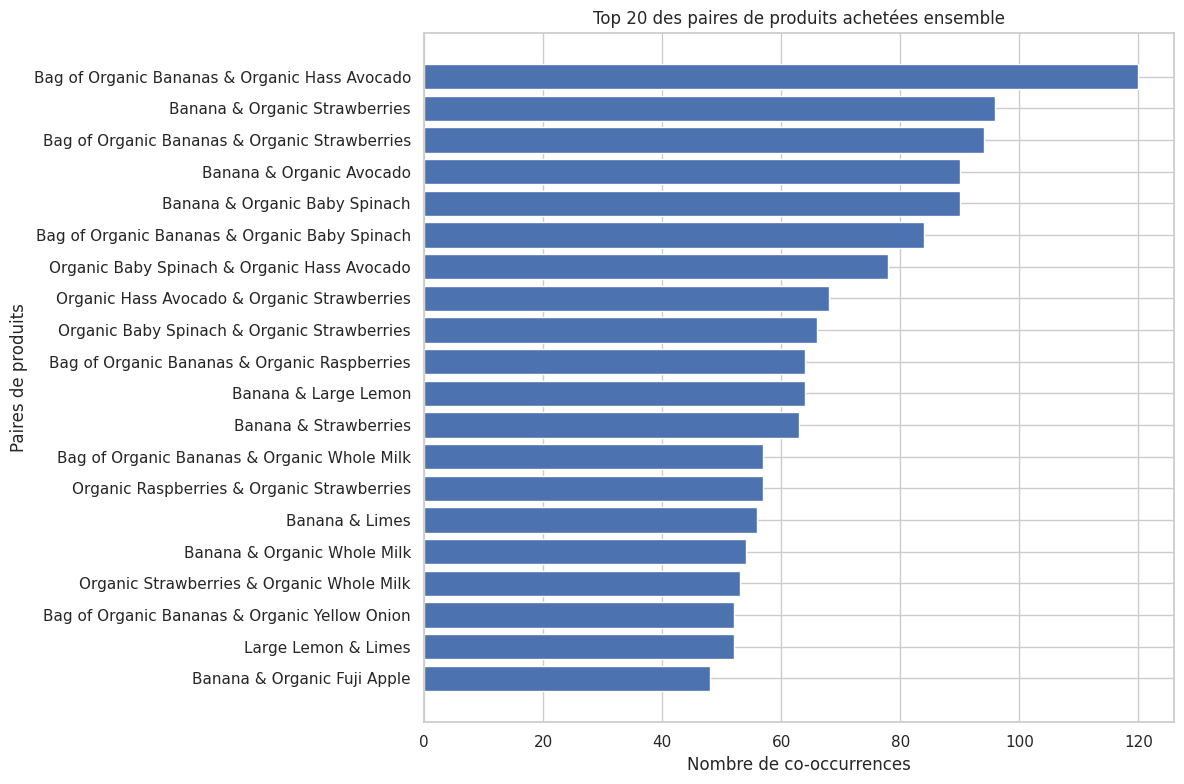

In [48]:
top_pairs = co_occurrence_df.head(20).copy()


top_pairs['pair'] = top_pairs['product_a'] + ' & ' + top_pairs['product_b']


plt.figure(figsize=(12, 8))
plt.barh(top_pairs['pair'], top_pairs['co_occurrence'])

plt.xlabel('Nombre de co-occurrences')
plt.ylabel('Paires de produits')
plt.title('Top 20 des paires de produits achetées ensemble')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [49]:
#question 7
def recommander(produit, n=5):
    """
    Recommande les n produits les plus souvent achetés
    avec le produit donné.
    """

    mask = ((co_occurrence_df['product_a'] == produit) |
            (co_occurrence_df['product_b'] == produit))

    resultats = co_occurrence_df[mask].copy()


    resultats['recommandation'] = resultats.apply(
        lambda row: row['product_b'] if row['product_a'] == produit
        else row['product_a'], axis=1
    )

    return resultats[['recommandation', 'co_occurrence']].head(n)


produits_test = ['Banana', 'Bag of Organic Bananas',
                 'Organic Strawberries', 'Large Lemon']

for produit in produits_test:
    print(recommander(produit))


            recommandation  co_occurrence
4390  Organic Strawberries             96
590        Organic Avocado             90
2847  Organic Baby Spinach             90
1656           Large Lemon             64
5791          Strawberries             63
            recommandation  co_occurrence
730   Organic Hass Avocado            120
735   Organic Strawberries             94
2504  Organic Baby Spinach             84
5322   Organic Raspberries             64
2209    Organic Whole Milk             57
              recommandation  co_occurrence
4390                  Banana             96
735   Bag of Organic Bananas             94
921     Organic Hass Avocado             68
4450    Organic Baby Spinach             66
4476     Organic Raspberries             57
               recommandation  co_occurrence
1656                   Banana             64
17740                   Limes             52
18513    Organic Baby Spinach             39
41316  Bag of Organic Bananas             35
13752  

## 09_evaluation

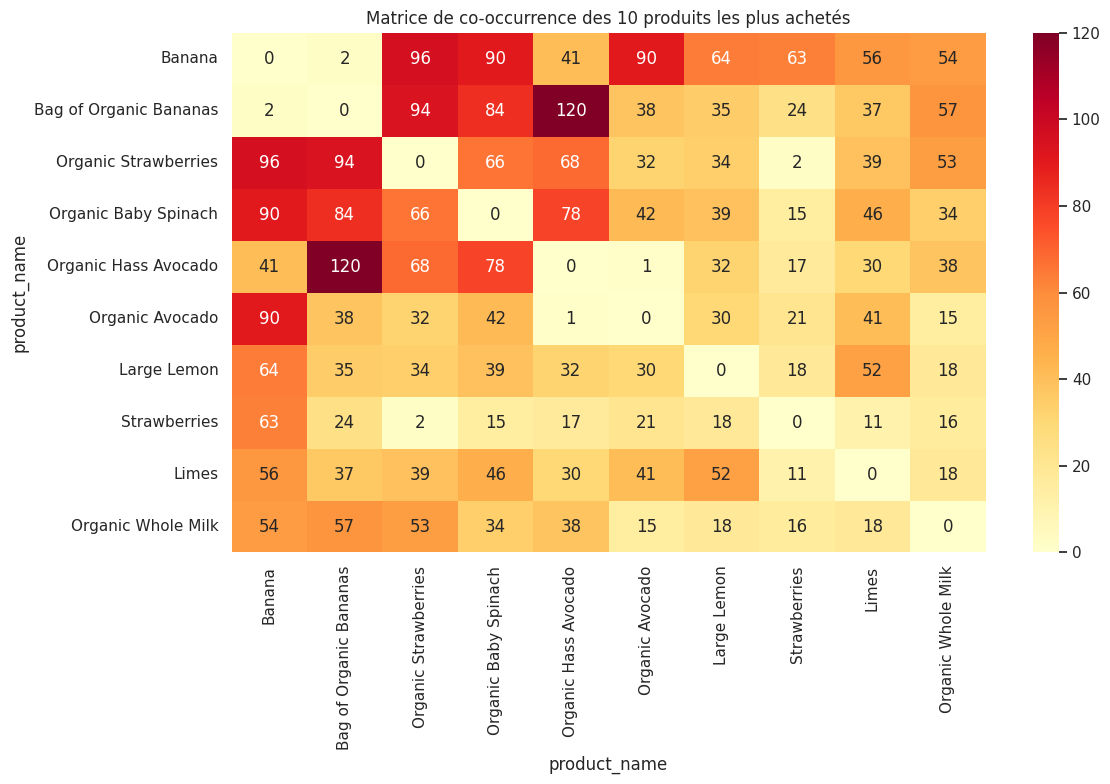

Commentaire : plus la couleur est foncée, plus les deux produits sont souvent achetés ensemble.

=== Evaluation des recommandations par fréquence ===
Nombre total de paires trouvées : 330145
Paires avec co-occurrence >= 50 : 19
Paires avec co-occurrence >= 20 : 187
Meilleure paire : Bag of Organic Bananas + Organic Hass Avocado (120 fois)

=== Qualité des recommandations ===

Produit : Banana
  → Organic Strawberries | co-occurrence : 96 | Qualité : 🟢 Forte
  → Organic Avocado | co-occurrence : 90 | Qualité : 🟢 Forte
  → Organic Baby Spinach | co-occurrence : 90 | Qualité : 🟢 Forte
  → Large Lemon | co-occurrence : 64 | Qualité : 🟢 Forte
  → Strawberries | co-occurrence : 63 | Qualité : 🟢 Forte

Produit : Bag of Organic Bananas
  → Organic Hass Avocado | co-occurrence : 120 | Qualité : 🟢 Forte
  → Organic Strawberries | co-occurrence : 94 | Qualité : 🟢 Forte
  → Organic Baby Spinach | co-occurrence : 84 | Qualité : 🟢 Forte
  → Organic Raspberries | co-occurrence : 64 | Qualité : 🟢 Fort

In [50]:
top_10_products = df_merged['product_name'].value_counts().head(10).index

co_matrix = pd.DataFrame(0, index=top_10_products, columns=top_10_products)

for _, row in co_occurrence_df.iterrows():
    a, b = row['product_a'], row['product_b']
    if a in top_10_products and b in top_10_products:
        co_matrix.loc[a, b] = row['co_occurrence']
        co_matrix.loc[b, a] = row['co_occurrence']

plt.figure(figsize=(12, 8))
sns.heatmap(co_matrix, annot=True, fmt='d', cmap='YlOrRd')
plt.title("Matrice de co-occurrence des 10 produits les plus achetés")
plt.tight_layout()
plt.show()
print("Commentaire : plus la couleur est foncée, plus les deux produits sont souvent achetés ensemble.")

print("\n=== Evaluation des recommandations par fréquence ===")
print(f"Nombre total de paires trouvées : {len(co_occurrence_df)}")
print(f"Paires avec co-occurrence >= 50 : {len(co_occurrence_df[co_occurrence_df['co_occurrence'] >= 50])}")
print(f"Paires avec co-occurrence >= 20 : {len(co_occurrence_df[co_occurrence_df['co_occurrence'] >= 20])}")
print(f"Meilleure paire : {co_occurrence_df.iloc[0]['product_a']} + {co_occurrence_df.iloc[0]['product_b']} ({co_occurrence_df.iloc[0]['co_occurrence']} fois)")

print("\n=== Qualité des recommandations ===")
for produit in ['Banana', 'Bag of Organic Bananas']:
    recs = recommander(produit)
    print(f"\nProduit : {produit}")
    for _, row in recs.iterrows():
        score = row['co_occurrence']
        qualite = "🟢 Forte" if score >= 50 else "🟡 Moyenne" if score >= 20 else "🔴 Faible"
        print(f"  → {row['recommandation']} | co-occurrence : {score} | Qualité : {qualite}")

L'analyse de la sortie de notre algorithme de co-occurrence nous permet de tirer des conclusions qualitatives très enrichissantes sur la pertinence de notre modèle :

Une forte cohérence culinaire et d'usage : Les associations trouvées par l'algorithme ont un sens logique indéniable. Par exemple, la recommandation de Limes (citrons verts) pour l'achat de Large Lemon (citrons jaunes), ou encore l'association Banana avec Organic Strawberries démontrent que le système arrive à capter des habitudes de consommation réelles (préparation de repas, achats d'agrumes, préparation de smoothies).

L'identification des paniers thématiques ("Healthy / Bio") : Qualitativement, nous constatons que les produits frais et biologiques dominent les relations les plus fortes (ex: Organic Baby Spinach avec Organic Hass Avocado). Le système réussit donc à grouper des articles appartenant à un même profil de consommation saine.

Confirmation du biais de popularité (Popularity Bias) : L'évaluation qualitative met également en lumière la principale limite de cette approche simple. Le produit Banana (et sa variante Bag of Organic Bananas) apparaît systématiquement dans le top des recommandations de presque tous les produits testés. Cela démontre que notre algorithme a tendance à "pousser" les bestsellers de manière globale, éclipsant parfois des associations de niche potentiellement plus intéressantes, mais moins fréquentes.

## 10_interpretation_and_limits

Cette approche basée sur la co-occurrence est simple à mettre en œuvre mais présente plusieurs limites. Les recommandations ne sont pas personnalisées, les produits populaires dominent souvent les résultats et les nouveaux produits ne peuvent pas être recommandés. De plus, une forte co-occurrence ne signifie pas qu'un produit provoque l'achat d'un autre. Des méthodes plus avancées comme Apriori, FP-Growth ou le filtrage collaboratif permettraient d'obtenir des recommandations plus pertinentes.
